Obtain the polynomic function from a melody

In [26]:
# Imports section
import numpy as np

from music21 import converter, note

from scipy.interpolate import make_interp_spline

import matplotlib.pyplot as plt

In [27]:
# Define the path for the MIDI file
midi_file_path = "C:/Users/cristinj/OneDrive - Universitetet i Oslo/Documents/Project1/melodic-contour-generation-based-on-sketches/irishtunes_dataset/Cooley's_0_2bars_23.midi"

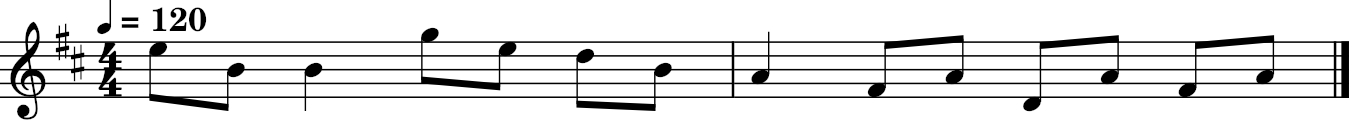

In [28]:
score = converter.parse(midi_file_path)
score.show()

In [29]:
def extract_melody(score):
    """
    A melody is an array of notes, where each note is represented as a dictionary with the following keys:
    - pitch: MIDI pitch number 
    - duration: duration in quarter lengths
    """
    melody = []
    score = score.flatten().notes

    for n in score:
        if isinstance(n, note.Note):
            melody.append({
                "pitch": n.pitch.midi,
                "duration": n.quarterLength,
            })
    return melody

In [30]:
def divide_into_ngrams(melody, n=4):
    """
    Divide the melody into n-grams of size n.
    Each n-gram is a list of notes.
    """
    ngrams = []
    for i in range(0, len(melody) - n + 1):
        ngram = melody[i:i+n]

        rel_pitch = []
        rel_duration = []

        # encode the pitch and duration of each note in the n-gram
        total_duration = 0
        first_pitch = ngram[0]['pitch']
        for note in ngram:
            rel_pitch.append(note['pitch'] - first_pitch)  # relative pitch encoding
            total_duration += note['duration']
        
        for note in ngram:
            rel_duration.append(note['duration'] / total_duration)  # relative duration encoding

        ngrams.append([rel_pitch, rel_duration]) # remove first position of rel_pitch (always 0)

    return ngrams

In [31]:
def fit_bspline(values):
    """
    Fit a B-spline to the given values (1D) and return a callable spline function
    """
    n = len(values)
    degree = n - 1

    x = np.linspace(0, 1, n)  # uniform parameterization
    spline = make_interp_spline(x, values, k=degree)

    return spline

In [32]:
melody = extract_melody(score)
for note in melody:
    print(f"Pitch: {note['pitch']}, Duration: {note['duration']}")
ngrams = divide_into_ngrams(melody, n=4)
print(ngrams)

Pitch: 76, Duration: 0.5
Pitch: 71, Duration: 0.5
Pitch: 71, Duration: 1.0
Pitch: 79, Duration: 0.5
Pitch: 76, Duration: 0.5
Pitch: 74, Duration: 0.5
Pitch: 71, Duration: 0.5
Pitch: 69, Duration: 1.0
Pitch: 66, Duration: 0.5
Pitch: 69, Duration: 0.5
Pitch: 62, Duration: 0.5
Pitch: 69, Duration: 0.5
Pitch: 66, Duration: 0.5
Pitch: 69, Duration: 0.5
[[[0, -5, -5, 3], [0.2, 0.2, 0.4, 0.2]], [[0, 0, 8, 5], [0.2, 0.4, 0.2, 0.2]], [[0, 8, 5, 3], [0.4, 0.2, 0.2, 0.2]], [[0, -3, -5, -8], [0.25, 0.25, 0.25, 0.25]], [[0, -2, -5, -7], [0.2, 0.2, 0.2, 0.4]], [[0, -3, -5, -8], [0.2, 0.2, 0.4, 0.2]], [[0, -2, -5, -2], [0.2, 0.4, 0.2, 0.2]], [[0, -3, 0, -7], [0.4, 0.2, 0.2, 0.2]], [[0, 3, -4, 3], [0.25, 0.25, 0.25, 0.25]], [[0, -7, 0, -3], [0.25, 0.25, 0.25, 0.25]], [[0, 7, 4, 7], [0.25, 0.25, 0.25, 0.25]]]


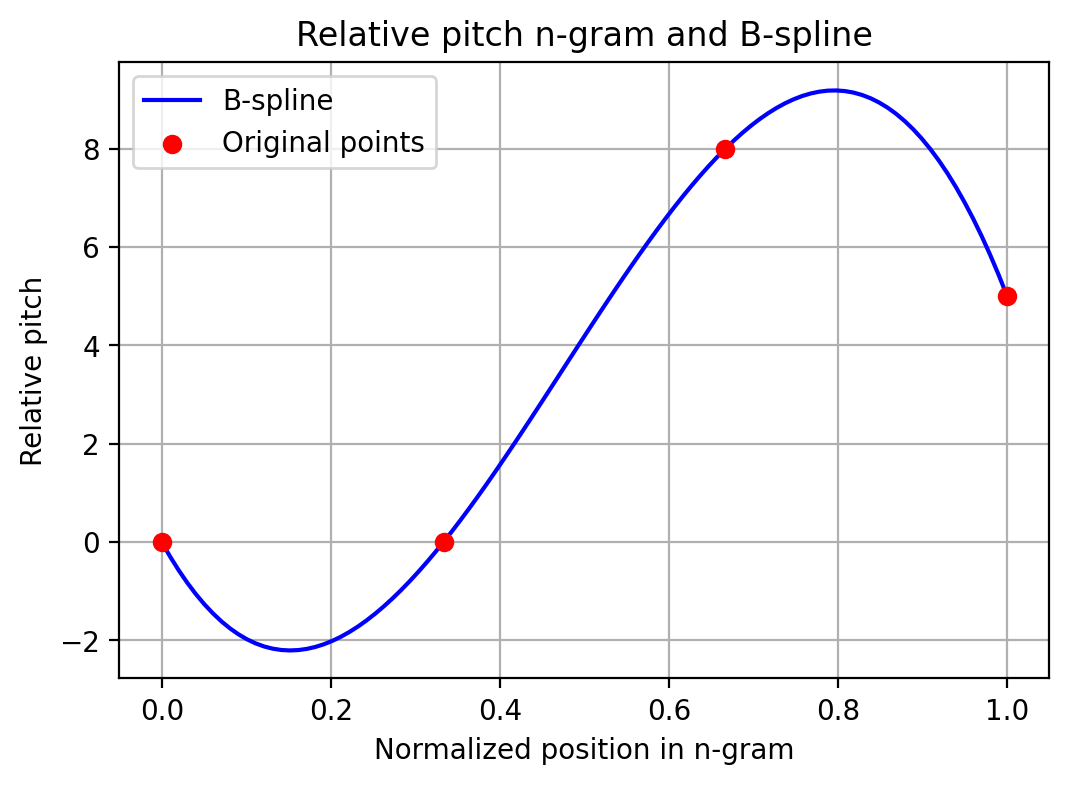

In [33]:
rel_pitch = ngrams[1][0]  # relative pitch array
pitch_spline = fit_bspline(rel_pitch)

# --- x-axis for original points ---
# n-1 points, evenly spaced in [0,1]
x_points = np.linspace(0, 1, len(rel_pitch))

# --- sample spline for smooth curve ---
x_spline = np.linspace(0, 1, 100)  # 100 points for smoothness
y_spline = pitch_spline(x_spline)

# --- plot ---
plt.figure(figsize=(6,4))
plt.plot(x_spline, y_spline, label='B-spline', color='blue')
plt.scatter(x_points, rel_pitch, color='red', label='Original points', zorder=5)
plt.title('Relative pitch n-gram and B-spline')
plt.xlabel('Normalized position in n-gram')
plt.ylabel('Relative pitch')
plt.legend()
plt.grid(True)
plt.show()